

# <div align="center">Biometric Assignment: Face Verification Across a 5-Year Age Gap</div>


Dataset:
    200 subjects
    2 images per subject
    Total = 400 images
    Minimum age gap = 5 years

Pipeline:
    1. Detect + align faces using MTCNN
    2. Extract face embeddings using FaceNet
       (InceptionResnetV1, pretrained='vggface2')
    3. Compute GENUINE scores
       → same subject: image_0 vs image_1
    4. Compute IMPOSTER scores
       → different subjects
    5. Repeat under 4 conditions:
       (a) Original image
       (b) Gaussian noise
       (c) Salt & Pepper noise
       (d) Synthetic degraded + resized image
    6. Compare the results

Dataset layout:
    DataSet/
        0000_0.jpg
        0000_1.jpg
        0001_0.jpg
        0001_1.jpg
        ...
        0099_0.jpg
        0099_1.jpg

Here:
    0000_0 and 0000_1 = same person
    0001_0 and 0001_1 = same person
    etc.

In [26]:
# CELL 2: Imports and Setup

import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

# Dataset path
DATASET_PATH = Path("dataset")

# Check dataset
print("Dataset exists:", DATASET_PATH.exists())
print("Dataset path:", DATASET_PATH)

Dataset exists: True
Dataset path: dataset


In [27]:
# CELL 3: Load image pairs

image_pairs = []

for subject_id in range(200):
    img0 = DATASET_PATH / f"{subject_id:04d}_0.jpg"
    img1 = DATASET_PATH / f"{subject_id:04d}_1.jpg"

    if img0.exists() and img1.exists():
        image_pairs.append((subject_id, img0, img1))

print("Number of subjects:", len(image_pairs))
print("Number of images:", len(image_pairs) * 2)

# Show first 5 pairs
for subject_id, img0, img1 in image_pairs[:5]:
    print(f"{subject_id:04d}: {img0.name}  <->  {img1.name}")

Number of subjects: 200
Number of images: 400
0000: 0000_0.jpg  <->  0000_1.jpg
0001: 0001_0.jpg  <->  0001_1.jpg
0002: 0002_0.jpg  <->  0002_1.jpg
0003: 0003_0.jpg  <->  0003_1.jpg
0004: 0004_0.jpg  <->  0004_1.jpg


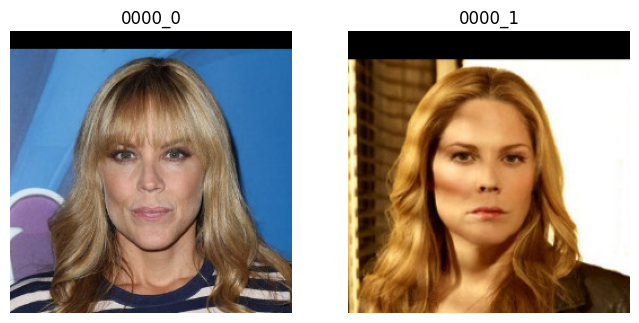

In [28]:
# CELL 4: Display one subject pair

subject_id, img0_path, img1_path = image_pairs[0]

img0 = cv2.cvtColor(cv2.imread(str(img0_path)), cv2.COLOR_BGR2RGB)
img1 = cv2.cvtColor(cv2.imread(str(img1_path)), cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(img0)
plt.title(f"{subject_id:04d}_0")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img1)
plt.title(f"{subject_id:04d}_1")
plt.axis("off")

plt.show()

In [29]:
# CELL 5: Import MTCNN and FaceNet

import torch
from facenet_pytorch import MTCNN, InceptionResnetV1

print("PyTorch version:", torch.__version__)
print("MTCNN and FaceNet imported successfully.")

PyTorch version: 2.2.2+cu121
MTCNN and FaceNet imported successfully.


In [30]:
# CELL 6: Initialize MTCNN

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

mtcnn = MTCNN(
    image_size=160,
    margin=20,
    keep_all=False,
    device=device
)

print("Device:", device)
print("MTCNN ready.")

Device: cpu
MTCNN ready.


In [31]:
# CELL 7: Detect and align faces

face0 = mtcnn(img0)
face1 = mtcnn(img1)

print("Face 0 detected:", face0 is not None)
print("Face 1 detected:", face1 is not None)

if face0 is not None:
    print("Face 0 shape:", face0.shape)

if face1 is not None:
    print("Face 1 shape:", face1.shape)

Face 0 detected: True
Face 1 detected: True
Face 0 shape: torch.Size([3, 160, 160])
Face 1 shape: torch.Size([3, 160, 160])


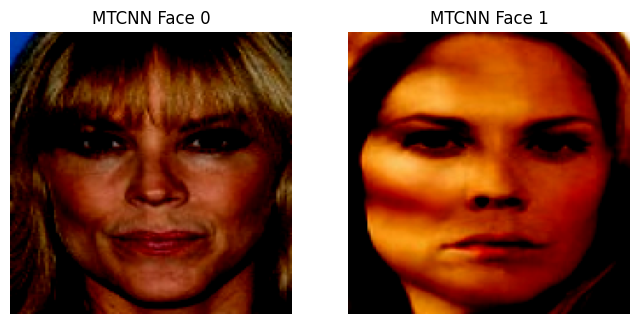

In [32]:
# CELL 8: Display aligned faces

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(face0.permute(1, 2, 0).clamp(0, 1))
plt.title("MTCNN Face 0")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(face1.permute(1, 2, 0).clamp(0, 1))
plt.title("MTCNN Face 1")
plt.axis("off")

plt.show()

In [33]:
# CELL 9: Load FaceNet

facenet = InceptionResnetV1(pretrained="vggface2").eval().to(device)

print("FaceNet loaded successfully.")
print("Embedding size: 512")

FaceNet loaded successfully.
Embedding size: 512


In [34]:
# CELL 10: Generate FaceNet embeddings

with torch.no_grad():
    embedding0 = facenet(face0.unsqueeze(0).to(device))
    embedding1 = facenet(face1.unsqueeze(0).to(device))

embedding0 = embedding0.cpu().numpy()[0]
embedding1 = embedding1.cpu().numpy()[0]

print("Embedding 0 shape:", embedding0.shape)
print("Embedding 1 shape:", embedding1.shape)

Embedding 0 shape: (512,)
Embedding 1 shape: (512,)


In [35]:
# CELL 11: Genuine similarity score

from sklearn.metrics.pairwise import cosine_similarity

genuine_score = cosine_similarity(
    embedding0.reshape(1, -1),
    embedding1.reshape(1, -1)
)[0][0]

print("Genuine cosine similarity:", round(genuine_score, 4))

Genuine cosine similarity: 0.5313


In [36]:
# CELL 12: Imposter similarity score

subject_id_2, img0_path_2, img1_path_2 = image_pairs[1]

img1_other = cv2.cvtColor(
    cv2.imread(str(img1_path_2)),
    cv2.COLOR_BGR2RGB
)

face_other = mtcnn(img1_other)

with torch.no_grad():
    embedding_other = facenet(
        face_other.unsqueeze(0).to(device)
    )

embedding_other = embedding_other.cpu().numpy()[0]

imposter_score = cosine_similarity(
    embedding0.reshape(1, -1),
    embedding_other.reshape(1, -1)
)[0][0]

print("Imposter cosine similarity:", round(imposter_score, 4))

Imposter cosine similarity: -0.0684


In [37]:
# CELL 13: Genuine scores for all subjects

genuine_scores = []
valid_subjects = []

for subject_id, img0_path, img1_path in image_pairs:

    # Read images
    img0 = cv2.cvtColor(
        cv2.imread(str(img0_path)),
        cv2.COLOR_BGR2RGB
    )

    img1 = cv2.cvtColor(
        cv2.imread(str(img1_path)),
        cv2.COLOR_BGR2RGB
    )

    # Detect and align faces
    face0 = mtcnn(img0)
    face1 = mtcnn(img1)

    # Skip if a face is not detected
    if face0 is None or face1 is None:
        print(f"Face not detected: {subject_id:04d}")
        continue

    # FaceNet embeddings
    with torch.no_grad():
        emb0 = facenet(face0.unsqueeze(0).to(device))
        emb1 = facenet(face1.unsqueeze(0).to(device))

    emb0 = emb0.cpu().numpy()
    emb1 = emb1.cpu().numpy()

    # Cosine similarity
    score = cosine_similarity(emb0, emb1)[0][0]

    genuine_scores.append(score)
    valid_subjects.append(subject_id)

print("Valid subjects:", len(valid_subjects))
print("Genuine scores:", len(genuine_scores))
print("Mean genuine score:", round(np.mean(genuine_scores), 4))

Valid subjects: 200
Genuine scores: 200
Mean genuine score: 0.745


In [38]:
# CELL 14: Imposter scores

imposter_scores = []

for i in range(len(valid_subjects)):

    # Current subject
    subject_a = valid_subjects[i]

    # Next subject (circular)
    subject_b = valid_subjects[(i + 1) % len(valid_subjects)]

    # Find their image paths
    _, img0_path_a, _ = image_pairs[subject_a]
    _, _, img1_path_b = image_pairs[subject_b]

    # Read images
    img_a = cv2.cvtColor(
        cv2.imread(str(img0_path_a)),
        cv2.COLOR_BGR2RGB
    )

    img_b = cv2.cvtColor(
        cv2.imread(str(img1_path_b)),
        cv2.COLOR_BGR2RGB
    )

    # MTCNN
    face_a = mtcnn(img_a)
    face_b = mtcnn(img_b)

    if face_a is None or face_b is None:
        continue

    # FaceNet
    with torch.no_grad():
        emb_a = facenet(face_a.unsqueeze(0).to(device))
        emb_b = facenet(face_b.unsqueeze(0).to(device))

    emb_a = emb_a.cpu().numpy()
    emb_b = emb_b.cpu().numpy()

    # Cosine similarity
    score = cosine_similarity(emb_a, emb_b)[0][0]

    imposter_scores.append(score)

print("Imposter comparisons:", len(imposter_scores))
print("Mean imposter score:", round(np.mean(imposter_scores), 4))

Imposter comparisons: 200
Mean imposter score: 0.0026


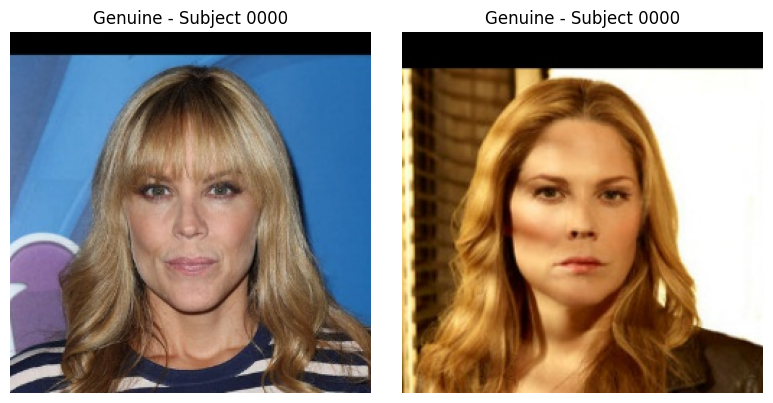

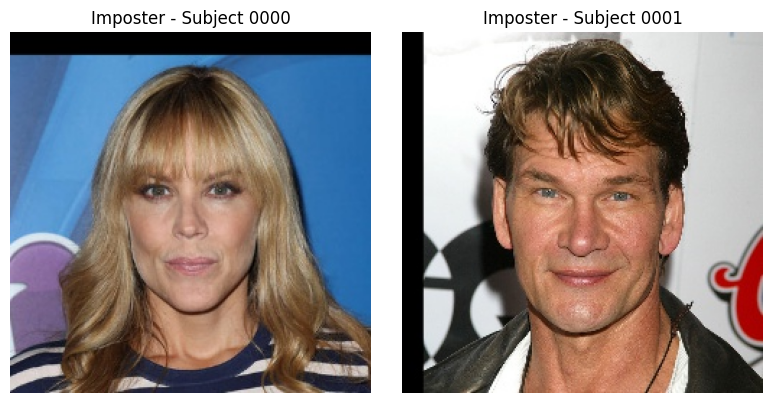

Saved:
results/genuine_pair.png
results/imposter_pair.png


In [39]:
# CELL 15: Save example genuine and imposter pairs

RESULTS_PATH = Path("results")
RESULTS_PATH.mkdir(exist_ok=True)

# ---------- Genuine pair ----------
genuine_a = cv2.imread(str(image_pairs[0][1]))
genuine_b = cv2.imread(str(image_pairs[0][2]))

genuine_a = cv2.cvtColor(genuine_a, cv2.COLOR_BGR2RGB)
genuine_b = cv2.cvtColor(genuine_b, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(genuine_a)
plt.title("Genuine - Subject 0000")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(genuine_b)
plt.title("Genuine - Subject 0000")
plt.axis("off")

plt.tight_layout()
plt.savefig(RESULTS_PATH / "genuine_pair.png", dpi=150)
plt.show()


# ---------- Imposter pair ----------
imposter_a = cv2.imread(str(image_pairs[0][1]))
imposter_b = cv2.imread(str(image_pairs[1][2]))

imposter_a = cv2.cvtColor(imposter_a, cv2.COLOR_BGR2RGB)
imposter_b = cv2.cvtColor(imposter_b, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(imposter_a)
plt.title("Imposter - Subject 0000")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(imposter_b)
plt.title("Imposter - Subject 0001")
plt.axis("off")

plt.tight_layout()
plt.savefig(RESULTS_PATH / "imposter_pair.png", dpi=150)
plt.show()

print("Saved:")
print(RESULTS_PATH / "genuine_pair.png")
print(RESULTS_PATH / "imposter_pair.png")

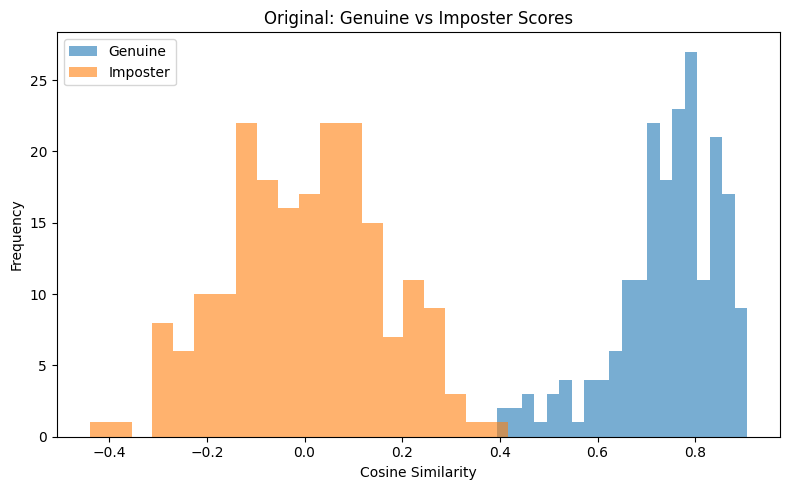

Mean Genuine : 0.745
Mean Imposter: 0.0026


In [40]:
# CELL 16: Original genuine vs imposter distribution

plt.figure(figsize=(8, 5))

plt.hist(
    genuine_scores,
    bins=20,
    alpha=0.6,
    label="Genuine"
)

plt.hist(
    imposter_scores,
    bins=20,
    alpha=0.6,
    label="Imposter"
)

plt.xlabel("Cosine Similarity")
plt.ylabel("Frequency")
plt.title("Original: Genuine vs Imposter Scores")
plt.legend()
plt.tight_layout()

plt.savefig(RESULTS_PATH / "original_score_distribution.png", dpi=150)
plt.show()

print("Mean Genuine :", round(np.mean(genuine_scores), 4))
print("Mean Imposter:", round(np.mean(imposter_scores), 4))

In [41]:
# CELL 17: Image degradation functions

def add_gaussian_noise(img, sigma=25):
    noise = np.random.normal(0, sigma, img.shape)
    noisy = img.astype(np.float32) + noise
    return np.clip(noisy, 0, 255).astype(np.uint8)


def add_salt_pepper_noise(img, amount=0.02):
    noisy = img.copy()

    h, w = img.shape[:2]
    total = int(amount * h * w)

    # Salt
    for _ in range(total // 2):
        y = np.random.randint(0, h)
        x = np.random.randint(0, w)
        noisy[y, x] = 255

    # Pepper
    for _ in range(total // 2):
        y = np.random.randint(0, h)
        x = np.random.randint(0, w)
        noisy[y, x] = 0

    return noisy


def synthetic_resize(img, scale=0.25):
    h, w = img.shape[:2]

    small = cv2.resize(
        img,
        (int(w * scale), int(h * scale)),
        interpolation=cv2.INTER_LINEAR
    )

    restored = cv2.resize(
        small,
        (w, h),
        interpolation=cv2.INTER_CUBIC
    )

    return restored


print("Degradation functions ready.")

Degradation functions ready.


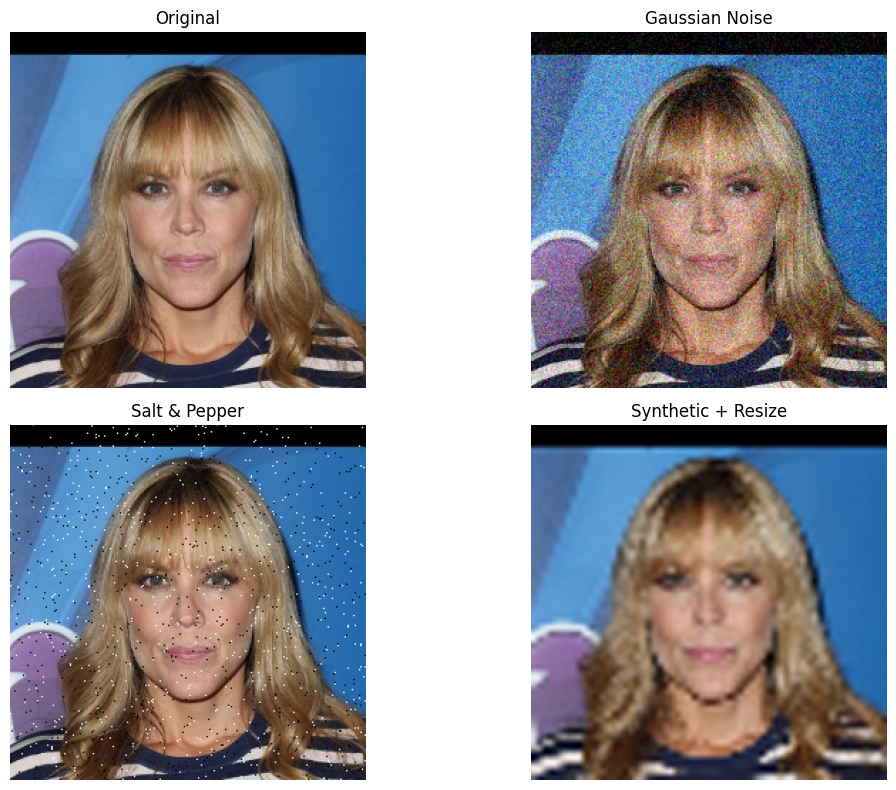

In [42]:
# CELL 18: Visualize the four conditions

original = cv2.imread(str(image_pairs[0][1]))
original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

gaussian = add_gaussian_noise(original)
salt_pepper = add_salt_pepper_noise(original)
synthetic = synthetic_resize(original)

images = [
    original,
    gaussian,
    salt_pepper,
    synthetic
]

titles = [
    "Original",
    "Gaussian Noise",
    "Salt & Pepper",
    "Synthetic + Resize"
]

plt.figure(figsize=(12, 8))

for i in range(4):
    plt.subplot(2, 2, i + 1)
    plt.imshow(images[i])
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.savefig(RESULTS_PATH / "four_conditions.png", dpi=150)
plt.show()

In [43]:
# CELL 19: Calculate scores for a condition

def get_embedding_from_image(img):
    face = mtcnn(img)

    if face is None:
        return None

    with torch.no_grad():
        embedding = facenet(
            face.unsqueeze(0).to(device)
        )

    return embedding.cpu().numpy()[0]


def calculate_condition_scores(condition_function):

    genuine = []
    imposter = []

    embeddings = []

    # Get embeddings for all images
    for subject_id, img0_path, img1_path in image_pairs:

        img0 = cv2.imread(str(img0_path))
        img1 = cv2.imread(str(img1_path))

        img0 = cv2.cvtColor(img0, cv2.COLOR_BGR2RGB)
        img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)

        img0 = condition_function(img0)
        img1 = condition_function(img1)

        emb0 = get_embedding_from_image(img0)
        emb1 = get_embedding_from_image(img1)

        if emb0 is None or emb1 is None:
            continue

        # Genuine
        genuine.append(
            cosine_similarity(
                emb0.reshape(1, -1),
                emb1.reshape(1, -1)
            )[0][0]
        )

        embeddings.append((emb0, emb1))

    # Lightweight impostor comparisons
    n = len(embeddings)

    for i in range(n):
        j = (i + 1) % n

        emb0 = embeddings[i][0]
        emb1 = embeddings[j][1]

        imposter.append(
            cosine_similarity(
                emb0.reshape(1, -1),
                emb1.reshape(1, -1)
            )[0][0]
        )

    return np.array(genuine), np.array(imposter)


print("Score function ready.")

Score function ready.


In [44]:
# CELL 20: Gaussian noise

gaussian_genuine, gaussian_imposter = calculate_condition_scores(
    add_gaussian_noise
)

print("Gaussian Genuine Mean:",
      round(np.mean(gaussian_genuine), 4))

print("Gaussian Imposter Mean:",
      round(np.mean(gaussian_imposter), 4))

Gaussian Genuine Mean: 0.6872
Gaussian Imposter Mean: 0.0497


In [45]:
# CELL 21: Salt & Pepper noise

sp_genuine, sp_imposter = calculate_condition_scores(
    add_salt_pepper_noise
)

print("Salt & Pepper Genuine Mean:",
      round(np.mean(sp_genuine), 4))

print("Salt & Pepper Imposter Mean:",
      round(np.mean(sp_imposter), 4))

Salt & Pepper Genuine Mean: 0.6729
Salt & Pepper Imposter Mean: 0.0161


In [46]:
# CELL 22: Synthetic degraded + resized

synthetic_genuine, synthetic_imposter = calculate_condition_scores(
    synthetic_resize
)

print("Synthetic Genuine Mean:",
      round(np.mean(synthetic_genuine), 4))

print("Synthetic Imposter Mean:",
      round(np.mean(synthetic_imposter), 4))

Synthetic Genuine Mean: 0.6229
Synthetic Imposter Mean: 0.0263


In [47]:
# CELL 23: Compare all conditions

results = pd.DataFrame({
    "Condition": [
        "Original",
        "Gaussian Noise",
        "Salt & Pepper",
        "Synthetic + Resize"
    ],

    "Mean Genuine": [
        np.mean(genuine_scores),
        np.mean(gaussian_genuine),
        np.mean(sp_genuine),
        np.mean(synthetic_genuine)
    ],

    "Mean Imposter": [
        np.mean(imposter_scores),
        np.mean(gaussian_imposter),
        np.mean(sp_imposter),
        np.mean(synthetic_imposter)
    ]
})

results["Separation"] = (
    results["Mean Genuine"] -
    results["Mean Imposter"]
)

results = results.round(4)

display(results)

results.to_csv(
    RESULTS_PATH / "comparison_results.csv",
    index=False
)

,Condition,Mean Genuine,Mean Imposter,Separation
0,Original,0.7450,0.0026,0.7424
1,Gaussian Noise,0.6872,0.0497,0.6375
2,Salt & Pepper,0.6729,0.0161,0.6569
3,Synthetic + Resize,0.6229,0.0263,0.5967


In [48]:
# CELL 24: FAR, FRR and EER

from sklearn.metrics import roc_curve, auc


def calculate_metrics(genuine, imposter):

    labels = np.concatenate([
        np.ones(len(genuine)),
        np.zeros(len(imposter))
    ])

    scores = np.concatenate([
        genuine,
        imposter
    ])

    fpr, tpr, thresholds = roc_curve(labels, scores)

    fnr = 1 - tpr

    index = np.nanargmin(np.abs(fpr - fnr))

    eer = (fpr[index] + fnr[index]) / 2
    threshold = thresholds[index]

    far = np.mean(imposter >= threshold)
    frr = np.mean(genuine < threshold)

    roc_auc = auc(fpr, tpr)

    return eer, threshold, far, frr, roc_auc


conditions = {
    "Original": (genuine_scores, imposter_scores),
    "Gaussian Noise": (gaussian_genuine, gaussian_imposter),
    "Salt & Pepper": (sp_genuine, sp_imposter),
    "Synthetic + Resize": (synthetic_genuine, synthetic_imposter)
}

metric_results = []

for name, (genuine, imposter) in conditions.items():

    eer, threshold, far, frr, roc_auc = calculate_metrics(
        genuine,
        imposter
    )

    metric_results.append({
        "Condition": name,
        "EER (%)": round(eer * 100, 2),
        "Threshold": round(threshold, 4),
        "FAR (%)": round(far * 100, 2),
        "FRR (%)": round(frr * 100, 2),
        "AUC": round(roc_auc, 4)
    })

metrics_df = pd.DataFrame(metric_results)

display(metrics_df)

metrics_df.to_csv(
    RESULTS_PATH / "biometric_metrics.csv",
    index=False
)

,Condition,EER (%),Threshold,FAR (%),FRR (%),AUC
0,Original,0.25,0.3938,0.5,0.0,1.0000
1,Gaussian Noise,1.25,0.3871,1.0,1.5,0.9991
2,Salt & Pepper,1.75,0.3178,2.0,1.5,0.9987
3,Synthetic + Resize,2.50,0.3056,2.5,2.5,0.9973


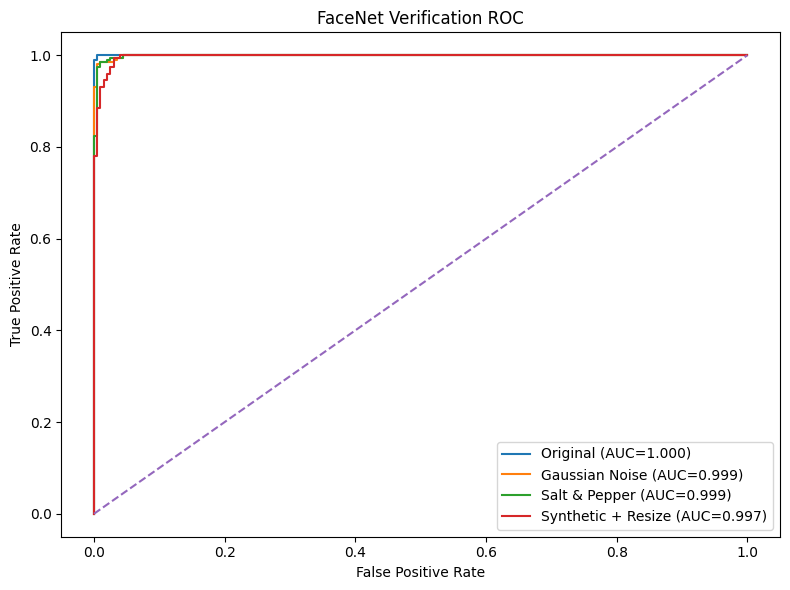

In [49]:
# CELL 25: ROC curves

plt.figure(figsize=(8, 6))

for name, (genuine, imposter) in conditions.items():

    labels = np.concatenate([
        np.ones(len(genuine)),
        np.zeros(len(imposter))
    ])

    scores = np.concatenate([
        genuine,
        imposter
    ])

    fpr, tpr, _ = roc_curve(labels, scores)
    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC={roc_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], "--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("FaceNet Verification ROC")
plt.legend()
plt.tight_layout()

plt.savefig(
    RESULTS_PATH / "roc_all_conditions.png",
    dpi=150
)

plt.show()

# Thank You